In [ ]:

# ============================================================
# TCC — MODELO 3
# PIM-PF SEM CÂMBIO
# ============================================================

pacotes <- c(
  "lmtest",
  "sandwich",
  "strucchange"
)

faltantes <- pacotes[
  !vapply(
    pacotes,
    requireNamespace,
    logical(1),
    quietly = TRUE
  )
]

if (length(faltantes) > 0) {
  install.packages(
    faltantes,
    repos = "https://cloud.r-project.org"
  )
}

invisible(lapply(
  pacotes,
  library,
  character.only = TRUE
))

cat("Pacotes carregados com sucesso.\n")


Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘zoo’


Loading required package: zoo


Attaching package: ‘zoo’


The following objects are masked from ‘package:base’:

    as.Date, as.Date.numeric




Pacotes carregados com sucesso.


In [ ]:

# MODELO 3 - PIM-PF SEM CÂMBIO

# 1. Inserção dos dados

Data <- seq(
  from = as.Date("1999-06-01"),
  to = as.Date("2026-07-01"),
  by = "month"
)

Selic <- c(
21,
19.5,
19.5,
19,
19,
19,
19,
19,
19,
18.5,
18.5,
18.5,
17.5,
16.5,
16.5,
16.5,
16.5,
16.5,
15.75,
15.25,
15.25,
15.75,
16.25,
16.75,
18.25,
19,
19,
19,
19,
19,
19,
19,
18.75,
18.5,
18.5,
18.5,
18.5,
18,
18,
18,
21,
22,
25,
25.5,
26.5,
26.5,
26.5,
26.5,
26,
24.5,
22,
20,
19,
17.5,
16.5,
16.5,
16.5,
16.25,
16,
16,
16,
16,
16,
16.25,
16.75,
17.25,
17.75,
18.25,
18.75,
19.25,
19.5,
19.75,
19.75,
19.75,
19.75,
19.5,
19,
18.5,
18,
17.25,
17.25,
16.5,
15.75,
15.75,
15.25,
14.75,
14.25,
14.25,
13.75,
13.25,
13.25,
13,
13,
12.75,
12.5,
12.5,
12,
11.5,
11.5,
11.25,
11.25,
11.25,
11.25,
11.25,
11.25,
11.25,
11.75,
11.75,
12.25,
13,
13,
13.75,
13.75,
13.75,
13.75,
12.75,
12.75,
11.25,
10.25,
10.25,
9.25,
8.75,
8.75,
8.75,
8.75,
8.75,
8.75,
8.75,
8.75,
8.75,
9.5,
9.5,
10.25,
10.75,
10.75,
10.75,
10.75,
10.75,
10.75,
11.25,
11.25,
11.75,
12,
12,
12.25,
12.5,
12.5,
12,
11.5,
11.5,
11,
10.5,
10.5,
9.75,
9,
8.5,
8.5,
8,
7.5,
7.5,
7.25,
7.25,
7.25,
7.25,
7.25,
7.25,
7.5,
8,
8,
8.5,
9,
9,
9.5,
10,
10,
10.5,
10.75,
10.75,
11,
11,
11,
11,
11,
11,
11.25,
11.25,
11.75,
12.25,
12.25,
12.75,
13.25,
13.25,
13.75,
14.25,
14.25,
14.25,
14.25,
14.25,
14.25,
14.25,
14.25,
14.25,
14.25,
14.25,
14.25,
14.25,
14.25,
14.25,
14,
14,
13.75,
13,
12.25,
12.25,
11.25,
11.25,
10.25,
9.25,
9.25,
8.25,
7.5,
7.5,
7,
7,
6.75,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6,
5.5,
5,
5,
4.5,
4.5,
4.25,
3.75,
3.75,
3,
2.25,
2.25,
2,
2,
2,
2,
2,
2,
2,
2.75,
2.75,
3.5,
4.25,
4.25,
5.25,
6.25,
7.75,
7.75,
9.25,
9.25,
10.75,
11.75,
11.75,
12.75,
13.25,
13.25,
13.75,
13.75,
13.75,
13.75,
13.75,
13.75,
13.75,
13.75,
13.75,
13.75,
13.75,
13.75,
13.25,
12.75,
12.75,
12.25,
11.75,
11.75,
11.25,
10.75,
10.75,
10.5,
10.5,
10.5,
10.5,
10.75,
10.75,
11.25,
12.25,
13.25,
13.25,
14.25,
14.25,
14.75,
15,
15,
15,
15,
15,
15,
15,
15,
15,
14.75,
14.5,
14.5,
14.25,
14.25
)

Desvio_Inflacao <- c(
-4.68,
-3.43,
-2.31,
-1.75,
-0.50,
0.65,
0.94,
2.85,
1.86,
0.92,
0.77,
0.47,
0.51,
1.06,
1.86,
1.77,
0.65,
-0.01,
-0.03,
1.92,
2.27,
2.44,
2.61,
3.04,
3.35,
3.05,
2.41,
2.46,
3.19,
3.61,
3.67,
4.12,
4.01,
4.25,
4.48,
4.27,
4.16,
4.01,
3.96,
4.43,
4.95,
7.43,
9.03,
5.97,
7.35,
8.07,
8.27,
8.74,
8.07,
6.93,
6.57,
6.64,
5.48,
2.52,
0.80,
2.21,
1.19,
0.39,
-0.24,
-0.35,
0.56,
1.31,
1.68,
1.20,
1.36,
1.74,
2.10,
2.91,
2.89,
3.04,
3.57,
3.55,
2.77,
2.07,
1.52,
1.54,
1.86,
1.72,
1.19,
1.20,
1.01,
0.82,
0.13,
-0.27,
-0.47,
-0.53,
-0.66,
-0.80,
-1.24,
-1.48,
-1.36,
-1.51,
-1.48,
-1.54,
-1.50,
-1.32,
-0.81,
-0.76,
-0.32,
-0.35,
-0.38,
-0.31,
-0.04,
0.06,
0.11,
0.23,
0.54,
1.08,
1.56,
1.87,
1.67,
1.75,
1.91,
1.89,
1.40,
1.34,
1.40,
1.11,
1.03,
0.70,
0.30,
0.00,
-0.14,
-0.16,
-0.33,
-0.28,
-0.19,
0.09,
0.33,
0.67,
0.76,
0.72,
0.34,
0.10,
-0.01,
0.20,
0.70,
1.13,
1.41,
1.49,
1.51,
1.80,
2.01,
2.05,
2.21,
2.37,
2.73,
2.81,
2.47,
2.14,
2.00,
1.72,
1.34,
0.74,
0.60,
0.49,
0.42,
0.70,
0.74,
0.78,
0.95,
1.03,
1.34,
1.65,
1.81,
2.09,
1.99,
2.00,
2.20,
1.77,
1.59,
1.36,
1.34,
1.27,
1.41,
1.09,
1.18,
1.65,
1.78,
1.87,
2.02,
2.00,
2.01,
2.25,
2.09,
2.06,
1.91,
2.64,
3.20,
3.63,
3.67,
3.97,
4.39,
5.06,
5.03,
4.99,
5.43,
5.98,
6.17,
6.21,
5.86,
4.89,
4.78,
4.82,
4.34,
4.24,
4.47,
3.98,
3.37,
2.49,
1.79,
0.85,
0.26,
0.07,
-0.42,
-0.90,
-1.50,
-1.79,
-2.04,
-1.96,
-1.80,
-1.70,
-1.55,
-1.64,
-1.66,
-1.82,
-1.74,
-1.64,
-0.11,
-0.02,
-0.31,
0.03,
0.06,
-0.45,
-0.75,
-0.47,
-0.36,
0.33,
0.69,
0.41,
-0.88,
-1.03,
-0.82,
-1.36,
-1.71,
-0.98,
0.06,
0.19,
0.01,
-0.70,
-1.60,
-2.12,
-1.87,
-1.69,
-1.56,
-0.86,
-0.08,
0.31,
0.52,
0.81,
1.45,
2.35,
3.01,
4.31,
4.60,
5.24,
5.93,
6.50,
6.92,
6.99,
6.31,
6.88,
7.04,
7.80,
8.63,
8.23,
8.39,
6.57,
5.23,
3.67,
2.97,
2.40,
2.29,
2.52,
2.35,
1.40,
0.93,
0.69,
-0.09,
0.74,
1.36,
1.94,
1.57,
1.43,
1.37,
1.51,
1.50,
0.93,
0.69,
0.93,
1.23,
1.50,
1.24,
1.42,
1.76,
1.87,
1.83,
1.56,
2.06,
2.48,
2.53,
2.32,
2.35,
2.23,
2.13,
2.17,
1.68,
1.46,
1.26,
1.44,
0.81,
1.14,
1.39,
1.72,
1.64,
1.44
)

Hiato_PIM <- c(
-1.6998794,
-3.2371575,
-1.9337112,
-0.9745328,
0.3149088,
-0.7642423,
-0.2004376,
-1.4490867,
-1.6184281,
-0.3020120,
0.3312703,
-0.2413962,
1.9101846,
2.3502482,
2.0601362,
0.5848715,
2.5128226,
1.4155111,
5.7332810,
2.9487595,
3.7908837,
2.1246321,
1.5764837,
2.1697782,
0.7194311,
0.2942779,
0.1394658,
-1.9471356,
-4.3636961,
-3.4192311,
-3.3044838,
-0.5384528,
1.4347921,
0.8945154,
0.9323081,
0.6616141,
0.7306667,
0.9981433,
-0.2920869,
0.1578085,
0.2605049,
-0.0960560,
-0.5596583,
-0.5952905,
-1.2560347,
-1.7770636,
-2.1849398,
-3.8781780,
-3.6709131,
-4.8183938,
-3.9617869,
-1.0859867,
-1.2428924,
-0.6398065,
-2.1901746,
-0.8514494,
0.2664232,
0.5984027,
0.9362428,
1.4619632,
1.4844721,
1.8092925,
2.4276696,
2.6265613,
1.5246372,
1.1819061,
1.4789315,
1.5567541,
-0.1711278,
0.4517694,
0.1696192,
3.2690040,
0.7141897,
-0.1961418,
-0.3797461,
-1.3307495,
-2.1567191,
-1.5902351,
-0.2026120,
-0.1726578,
0.2905968,
-0.5954680,
-0.4544372,
0.0314007,
-1.5919411,
-1.1067243,
-1.5524435,
-2.8725561,
-2.2809250,
-1.3650003,
-1.0023268,
-1.4079060,
-0.4951295,
0.5824733,
1.3359696,
1.3453925,
1.7781419,
1.2121192,
2.4500528,
1.1001328,
3.9293146,
2.6488861,
2.7974286,
4.3659724,
4.0360130,
4.1131474,
4.1347393,
4.8447455,
6.0252933,
6.5249720,
5.2194889,
6.5024037,
3.4784846,
-2.9404882,
-13.6181122,
-11.8829175,
-9.9197279,
-9.5924129,
-8.4958100,
-7.5003072,
-6.2392573,
-5.2704243,
-3.9304906,
-2.7458220,
-0.8119165,
0.2218364,
0.4531245,
1.7129435,
1.3431720,
3.4911664,
3.6543912,
3.1542189,
2.5268701,
1.7232064,
1.2752994,
1.3214880,
0.8127892,
1.4415854,
1.7735844,
1.9519714,
3.0798825,
3.2691827,
0.6112237,
3.5856261,
1.5496617,
1.2952505,
0.5136238,
-1.1265293,
-2.2984034,
-1.8232149,
0.7667052,
-3.5211801,
-2.7863978,
-3.2258359,
-3.3150153,
-2.7584593,
-2.5397504,
-1.2329103,
0.8938341,
-1.0558476,
0.4939342,
-0.7668897,
-0.0702574,
0.9425978,
-1.8823490,
0.2028093,
2.0420973,
1.9110098,
2.4169678,
2.0864834,
2.5255377,
3.2219401,
2.3008292,
3.1746030,
-0.1477458,
1.8291082,
2.5679449,
2.4769865,
2.0455876,
1.4151107,
-1.1348966,
1.7671420,
2.5334943,
3.2480553,
3.6943016,
3.2853292,
1.0317680,
1.9071366,
1.4333356,
1.6027559,
0.0811223,
-0.5754315,
-0.7840954,
-2.1399643,
-1.2701587,
-3.0551668,
-2.8594795,
-4.0682665,
-5.0381789,
-3.9542538,
-4.5685264,
-3.7114393,
-3.3509681,
-2.7082820,
-3.8106597,
-2.8671615,
-4.3976511,
-3.2512431,
-4.5673710,
-3.3019932,
-1.5624117,
-0.7798689,
0.3489809,
-1.1075340,
-1.0873976,
-0.5559230,
0.3708861,
0.5734764,
0.6545793,
1.0270204,
1.9077060,
2.4207678,
5.1792733,
2.8418832,
2.1158331,
3.6993507,
4.0113985,
-7.2909362,
4.2898480,
3.9736101,
3.0891447,
0.1347895,
1.6572987,
1.6095072,
1.5169438,
1.0649843,
1.4622972,
0.9061201,
1.6432472,
1.6233214,
0.7782923,
0.3857624,
1.4474472,
1.4979690,
3.8971260,
1.5613017,
0.2313486,
1.5996314,
2.3961322,
-5.5087411,
-24.2052366,
-18.2134051,
-9.7788534,
-1.7302079,
1.2377735,
3.9711497,
5.5610031,
5.9413759,
5.4357615,
6.0220575,
4.5651237,
2.3488094,
0.3599943,
1.5095037,
1.1946902,
-0.2624049,
-0.3347806,
-0.7001028,
-1.1560806,
-1.0997387,
0.3867547,
0.1051618,
1.0216950,
0.1068790,
0.7179762,
0.1579312,
0.1118784,
1.0920412,
-0.3799177,
-2.0026609,
-0.5083972,
-0.5590341,
-0.4633043,
-0.7776911,
-1.0006969,
-0.3840549,
-0.9441588,
-0.3277912,
-0.7710206,
-1.4723633,
-1.0732760,
-1.5146486,
-1.2155790,
-0.2117673,
1.4517608,
-0.0018228,
-0.1474773,
0.0306791,
-0.3812037,
-1.9650813,
2.7878320,
1.0895193,
0.7368224,
1.5725931,
1.4868799,
0.8255969,
0.5864031,
0.3039442,
-0.2557282,
1.1694889,
0.4062713,
-0.5164656,
0.2835434,
-0.1488257,
0.6195263,
0.1026632,
0.0961065,
-0.1823821,
-2.2614410,
-0.3317375,
0.5068055,
0.5089144,
1.5618997,
0.4173964,
-1.2634182,
-1.3087565
)



In [ ]:

# ============================================================
# MODELO 3 — CONSTRUÇÃO E VALIDAÇÃO DA BASE
# ============================================================

# 1. Conferir os vetores originais
tamanhos <- c(
  Data = length(Data),
  Selic = length(Selic),
  Desvio_Inflacao = length(Desvio_Inflacao),
  Hiato_PIM = length(Hiato_PIM)
)

print(tamanhos)

stopifnot(
  all(tamanhos == 326),
  inherits(Data, "Date"),
  identical(Data[1], as.Date("1999-06-01")),
  identical(tail(Data, 1), as.Date("2026-07-01")),
  !anyDuplicated(Data),
  all(!is.na(Selic)),
  all(!is.na(Desvio_Inflacao)),
  all(!is.na(Hiato_PIM)),
  all(is.finite(Selic)),
  all(is.finite(Desvio_Inflacao)),
  all(is.finite(Hiato_PIM))
)

# 2. Construir a base original
base_m3 <- data.frame(
  Data = Data,
  Selic = Selic,
  Desvio_Inflacao = Desvio_Inflacao,
  Hiato_PIM = Hiato_PIM
)

# 3. Criar as defasagens de um mês
dados_modelo3 <- data.frame(
  Data = base_m3$Data[-1],
  Selic = base_m3$Selic[-1],
  Selic_L1 = head(base_m3$Selic, -1),
  Desvio_Inflacao_L1 = head(
    base_m3$Desvio_Inflacao, -1
  ),
  Hiato_PIM_L1 = head(base_m3$Hiato_PIM, -1)
)

# 4. Validar a base efetiva
stopifnot(
  nrow(dados_modelo3) == 325,
  all(complete.cases(dados_modelo3)),
  identical(
    dados_modelo3$Data[1],
    as.Date("1999-07-01")
  ),
  identical(
    tail(dados_modelo3$Data, 1),
    as.Date("2026-07-01")
  )
)

cat("\n========== VALIDAÇÃO DA BASE — MODELO 3 ==========\n")
cat("Observações originais:", nrow(base_m3), "\n")
cat("Observações efetivas:", nrow(dados_modelo3), "\n")
cat("Primeiro mês:",
    format(min(dados_modelo3$Data), "%m/%Y"), "\n")
cat("Último mês:",
    format(max(dados_modelo3$Data), "%m/%Y"), "\n")

cat("\n========== RESUMO DOS DADOS ==========\n")
print(summary(base_m3))

cat("\n========== PRIMEIRAS OBSERVAÇÕES ==========\n")
print(head(dados_modelo3, 3))

cat("\n========== ÚLTIMAS OBSERVAÇÕES ==========\n")
print(tail(dados_modelo3, 3))


           Data           Selic Desvio_Inflacao       Hiato_PIM 
            326             326             326             326 

========== VALIDAÇÃO DA BASE — MODELO 3 ==========
Observações originais: 326 
Observações efetivas: 325 
Primeiro mês: 07/1999 
Último mês: 07/2026 

========== RESUMO DOS DADOS ==========
      Data                Selic       Desvio_Inflacao    Hiato_PIM        
 Min.   :1999-06-01   Min.   : 2.00   Min.   :-4.680   Min.   :-24.20524  
 1st Qu.:2006-03-08   1st Qu.: 9.25   1st Qu.: 0.145   1st Qu.: -1.13280  
 Median :2012-12-16   Median :12.50   Median : 1.435   Median :  0.30943  
 Mean   :2012-12-15   Mean   :12.57   Mean   : 1.719   Mean   : -0.01213  
 3rd Qu.:2019-09-23   3rd Qu.:15.62   3rd Qu.: 2.513   3rd Qu.:  1.60197  
 Max.   :2026-07-01   Max.   :26.50   Max.   : 9.030   Max.   :  6.52497  

========== PRIMEIRAS OBSERVAÇÕES ==========
        Data Selic Selic_L1 Desvio_Inflacao_L1 Hiato_PIM_L1
1 1999-07-01  19.5     21.0              -4.68   

In [ ]:

# ============================================================
# MODELO 3 — MQO E NEWEY-WEST
# ============================================================

formula_m3 <- Selic ~
  Selic_L1 +
  Desvio_Inflacao_L1 +
  Hiato_PIM_L1

modelo3 <- lm(
  formula_m3,
  data = dados_modelo3
)

cat("\n========== MQO — MODELO 3 ==========\n")
print(summary(modelo3))

# Mesma configuração dos Modelos 1 e 2
vcov_NW_m3 <- sandwich::NeweyWest(
  modelo3,
  lag = NULL,
  prewhite = FALSE,
  adjust = TRUE
)

cat("\n========== COEFICIENTES COM NEWEY-WEST ==========\n")
print(
  lmtest::coeftest(
    modelo3,
    vcov. = vcov_NW_m3
  )
)

cat("\n========== INDICADORES DO MODELO ==========\n")

indicadores_m3 <- data.frame(
  Observacoes = nobs(modelo3),
  R2 = summary(modelo3)$r.squared,
  R2_Ajustado = summary(modelo3)$adj.r.squared,
  AIC = AIC(modelo3),
  BIC = BIC(modelo3)
)

print(indicadores_m3, row.names = FALSE)



========== MQO — MODELO 3 ==========

Call:
lm(formula = formula_m3, data = dados_modelo3)

Residuals:
     Min       1Q   Median       3Q      Max 
-2.40231 -0.18408 -0.00854  0.22976  2.89862 

Coefficients:
                   Estimate Std. Error t value Pr(>|t|)    
(Intercept)        0.135514   0.074190   1.827   0.0687 .  
Selic_L1           0.975028   0.006008 162.280  < 2e-16 ***
Desvio_Inflacao_L1 0.091853   0.012463   7.370 1.46e-12 ***
Hiato_PIM_L1       0.053532   0.008273   6.470 3.65e-10 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.4786 on 321 degrees of freedom
Multiple R-squared:  0.9905,	Adjusted R-squared:  0.9904 
F-statistic: 1.118e+04 on 3 and 321 DF,  p-value: < 2.2e-16


========== COEFICIENTES COM NEWEY-WEST ==========

t test of coefficients:

                   Estimate Std. Error t value  Pr(>|t|)    
(Intercept)        0.135514   0.122304  1.1080    0.2687    
Selic_L1           0.975028   0.010042 97.099

In [ ]:

# ============================================================
# MODELO 3 — PARÂMETROS ESTRUTURAIS
# NEWEY-WEST + MÉTODO DELTA
# ============================================================

# 1. Coeficientes auxiliares
b_m3 <- coef(modelo3)

# 2. Matriz de covariância Newey-West
V_m3 <- vcov_NW_m3

stopifnot(
  identical(names(b_m3), colnames(V_m3)),
  all(is.finite(b_m3)),
  all(is.finite(V_m3))
)

# 3. Recuperação dos parâmetros estruturais
rho_m3 <- unname(b_m3["Selic_L1"])
denominador_m3 <- 1 - rho_m3

if (abs(denominador_m3) < 1e-8) {
  stop("Rho muito próximo de 1: recuperação instável.")
}

parametros_m3 <- c(
  alpha = unname(b_m3["(Intercept)"]),
  rho = rho_m3,
  phi_pi = unname(
    b_m3["Desvio_Inflacao_L1"]
  ) / denominador_m3,
  phi_y = unname(
    b_m3["Hiato_PIM_L1"]
  ) / denominador_m3
)

# 4. Jacobiana para o método delta
J_m3 <- matrix(
  0,
  nrow = 4,
  ncol = length(b_m3),
  dimnames = list(
    names(parametros_m3),
    names(b_m3)
  )
)

J_m3["alpha", "(Intercept)"] <- 1
J_m3["rho", "Selic_L1"] <- 1

J_m3["phi_pi", "Selic_L1"] <-
  unname(b_m3["Desvio_Inflacao_L1"]) /
  denominador_m3^2

J_m3["phi_pi", "Desvio_Inflacao_L1"] <-
  1 / denominador_m3

J_m3["phi_y", "Selic_L1"] <-
  unname(b_m3["Hiato_PIM_L1"]) /
  denominador_m3^2

J_m3["phi_y", "Hiato_PIM_L1"] <-
  1 / denominador_m3

# 5. Variância-covariância dos parâmetros estruturais
V_estrutural_m3 <- J_m3 %*%
  V_m3 %*%
  t(J_m3)

ep_m3 <- sqrt(diag(V_estrutural_m3))

# 6. Estatísticas t e valores-p
estatistica_t_m3 <- parametros_m3 / ep_m3

valor_p_m3 <- 2 * pt(
  abs(estatistica_t_m3),
  df = df.residual(modelo3),
  lower.tail = FALSE
)

# 7. Tabela consolidada
tabela_estrutural_m3 <- data.frame(
  Parametro = names(parametros_m3),
  Estimativa = as.numeric(parametros_m3),
  Erro_padrao_NW = as.numeric(ep_m3),
  Estatistica_t = as.numeric(estatistica_t_m3),
  Valor_p = as.numeric(valor_p_m3)
)

stopifnot(
  nrow(tabela_estrutural_m3) == 4,
  all(is.finite(
    as.matrix(tabela_estrutural_m3[, 2:5])
  ))
)

cat("\n========== PARÂMETROS ESTRUTURAIS — MODELO 3 ==========\n")

print(
  transform(
    tabela_estrutural_m3,
    Estimativa = round(Estimativa, 6),
    Erro_padrao_NW = round(Erro_padrao_NW, 6),
    Estatistica_t = round(Estatistica_t, 4),
    Valor_p = signif(Valor_p, 6)
  ),
  row.names = FALSE
)



========== PARÂMETROS ESTRUTURAIS — MODELO 3 ==========
 Parametro Estimativa Erro_padrao_NW Estatistica_t      Valor_p
     alpha   0.135514       0.122304        1.1080  2.68688e-01
       rho   0.975028       0.010042       97.0997 5.23620e-240
    phi_pi   3.678296       2.016448        1.8241  6.90595e-02
     phi_y   2.143730       0.926182        2.3146  2.12662e-02


In [ ]:

# ============================================================
# MODELO 3 — JANELAS MÓVEIS DE 84 MESES
# ============================================================

tamanho_janela_m3 <- 84
n_total_m3 <- nrow(dados_modelo3)
n_janelas_m3 <- n_total_m3 - tamanho_janela_m3 + 1

stopifnot(
  n_total_m3 == 325,
  n_janelas_m3 == 242,
  all(complete.cases(dados_modelo3))
)

estimar_janela_m3 <- function(inicio) {

  fim <- inicio + tamanho_janela_m3 - 1L
  dados_janela <- dados_modelo3[inicio:fim, ]

  modelo <- lm(formula_m3, data = dados_janela)

  V <- sandwich::NeweyWest(
    modelo,
    lag = NULL,
    prewhite = FALSE,
    adjust = TRUE
  )

  teste <- lmtest::coeftest(modelo, vcov. = V)
  b <- coef(modelo)

  rho <- unname(b["Selic_L1"])
  d <- 1 - rho

  if (abs(d) < 1e-8) {
    stop("Rho muito próximo de 1 na janela ", inicio)
  }

  # Recuperação estrutural
  parametros <- c(
    alpha = unname(b["(Intercept)"]),
    rho = rho,
    phi_pi = unname(b["Desvio_Inflacao_L1"]) / d,
    phi_y = unname(b["Hiato_PIM_L1"]) / d
  )

  # Jacobiana do método delta
  J <- matrix(
    0,
    nrow = 4,
    ncol = 4,
    dimnames = list(names(parametros), names(b))
  )

  J["alpha", "(Intercept)"] <- 1
  J["rho", "Selic_L1"] <- 1

  J["phi_pi", "Selic_L1"] <-
    unname(b["Desvio_Inflacao_L1"]) / d^2

  J["phi_pi", "Desvio_Inflacao_L1"] <- 1 / d

  J["phi_y", "Selic_L1"] <-
    unname(b["Hiato_PIM_L1"]) / d^2

  J["phi_y", "Hiato_PIM_L1"] <- 1 / d

  V_estrutural <- J %*% V %*% t(J)

  ep <- sqrt(diag(V_estrutural))

  p_estrutural <- 2 * pt(
    abs(parametros / ep),
    df = df.residual(modelo),
    lower.tail = FALSE
  )

  resultado <- data.frame(
    Data = max(dados_janela$Data),

    beta_selic = unname(b["Selic_L1"]),
    beta_inflacao = unname(b["Desvio_Inflacao_L1"]),
    beta_hiato = unname(b["Hiato_PIM_L1"]),

    ep_beta_selic = unname(teste["Selic_L1", 2]),
    ep_beta_inflacao = unname(teste["Desvio_Inflacao_L1", 2]),
    ep_beta_hiato = unname(teste["Hiato_PIM_L1", 2]),

    p_beta_selic = unname(teste["Selic_L1", 4]),
    p_beta_inflacao = unname(teste["Desvio_Inflacao_L1", 4]),
    p_beta_hiato = unname(teste["Hiato_PIM_L1", 4]),

    alpha = unname(parametros["alpha"]),
    rho = unname(parametros["rho"]),
    phi_pi = unname(parametros["phi_pi"]),
    phi_y = unname(parametros["phi_y"]),

    ep_phi_pi = unname(ep["phi_pi"]),
    ep_phi_y = unname(ep["phi_y"]),

    p_phi_pi = unname(p_estrutural["phi_pi"]),
    p_phi_y = unname(p_estrutural["phi_y"]),

    R2 = summary(modelo)$r.squared,
    AIC = AIC(modelo),
    BIC = BIC(modelo)
  )

  rownames(resultado) <- NULL
  resultado
}

resultados_janelas_m3 <- do.call(
  rbind,
  lapply(seq_len(n_janelas_m3), estimar_janela_m3)
)

rownames(resultados_janelas_m3) <- NULL

# Validações
stopifnot(
  nrow(resultados_janelas_m3) == 242,
  resultados_janelas_m3$Data[1] == as.Date("2006-06-01"),
  tail(resultados_janelas_m3$Data, 1) ==
    as.Date("2026-07-01"),
  all(complete.cases(resultados_janelas_m3)),
  all(is.finite(as.matrix(resultados_janelas_m3[, -1])))
)

cat("\n========== VALIDAÇÃO DAS JANELAS — MODELO 3 ==========\n")
cat("Observações:", n_total_m3, "\n")
cat("Tamanho da janela:", tamanho_janela_m3, "\n")
cat("Janelas estimadas:", nrow(resultados_janelas_m3), "\n")
cat("Primeiro encerramento:",
    format(resultados_janelas_m3$Data[1], "%m/%Y"), "\n")
cat("Último encerramento:",
    format(tail(resultados_janelas_m3$Data, 1), "%m/%Y"), "\n")



========== VALIDAÇÃO DAS JANELAS — MODELO 3 ==========
Observações: 325 
Tamanho da janela: 84 
Janelas estimadas: 242 
Primeiro encerramento: 06/2006 
Último encerramento: 07/2026 


In [ ]:

# ============================================================
# MODELO 3 — TABELAS DAS JANELAS MÓVEIS
# ============================================================

colunas_p_m3 <- c(
  "p_beta_selic",
  "p_beta_inflacao",
  "p_beta_hiato"
)

nomes_m3 <- c(
  "Selic defasada",
  "Desvio da inflação",
  "Hiato do produto (PIM-PF)"
)

quantidades_m3 <- sapply(
  colunas_p_m3,
  function(coluna) {
    sum(resultados_janelas_m3[[coluna]] < 0.05)
  }
)

frequencia_m3 <- data.frame(
  Coeficiente = nomes_m3,
  Total_janelas = nrow(resultados_janelas_m3),
  Janelas_significativas = as.integer(quantidades_m3),
  Percentual = round(
    100 * quantidades_m3 / nrow(resultados_janelas_m3),
    3
  )
)

cat("\n========== FREQUÊNCIA DE SIGNIFICÂNCIA ==========\n")
print(frequencia_m3, row.names = FALSE)

parametros_m3_janelas <- c(
  "rho", "phi_pi", "phi_y"
)

resumo_estrutural_janelas_m3 <- data.frame(
  Parametro = parametros_m3_janelas,
  Media = sapply(parametros_m3_janelas, function(x)
    mean(resultados_janelas_m3[[x]])),
  Minimo = sapply(parametros_m3_janelas, function(x)
    min(resultados_janelas_m3[[x]])),
  Maximo = sapply(parametros_m3_janelas, function(x)
    max(resultados_janelas_m3[[x]]))
)

cat("\n========== RESUMO DOS PARÂMETROS ESTRUTURAIS ==========\n")

print(
  transform(
    resumo_estrutural_janelas_m3,
    Media = round(Media, 5),
    Minimo = round(Minimo, 5),
    Maximo = round(Maximo, 5)
  ),
  row.names = FALSE
)

cat("\n========== PRIMEIRAS JANELAS ==========\n")
print(head(resultados_janelas_m3, 6))

cat("\n========== ÚLTIMAS JANELAS ==========\n")
print(tail(resultados_janelas_m3, 6))



========== FREQUÊNCIA DE SIGNIFICÂNCIA ==========
               Coeficiente Total_janelas Janelas_significativas Percentual
            Selic defasada           242                    242    100.000
        Desvio da inflação           242                    145     59.917
 Hiato do produto (PIM-PF)           242                    223     92.149

========== RESUMO DOS PARÂMETROS ESTRUTURAIS ==========
 Parametro   Media    Minimo   Maximo
       rho 0.96074   0.90659  1.04359
    phi_pi 2.24268 -29.89095 28.61053
     phi_y 1.26180 -92.87575 84.01430

========== PRIMEIRAS JANELAS ==========
        Data beta_selic beta_inflacao beta_hiato ep_beta_selic ep_beta_inflacao
1 2006-06-01  0.9822491    0.07529992  0.1582463    0.04910992       0.07282482
2 2006-07-01  1.0017423    0.05207810  0.1618146    0.05842126       0.09163859
3 2006-08-01  0.9835596    0.08264796  0.1714566    0.05988062       0.09807932
4 2006-09-01  0.9693505    0.09410826  0.1648906    0.06490570       0.10908135

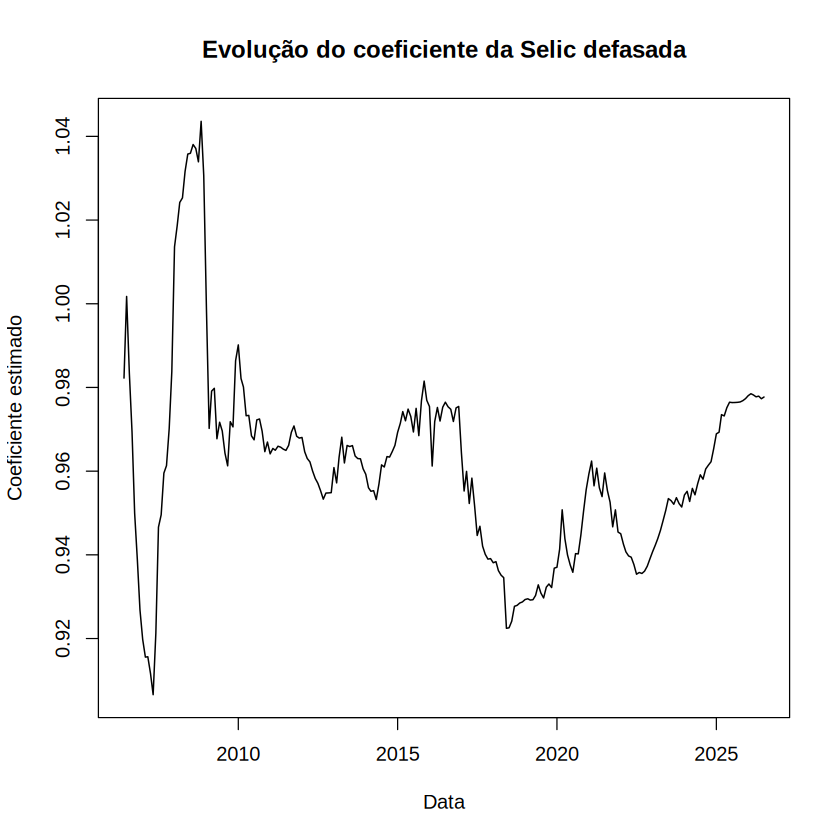

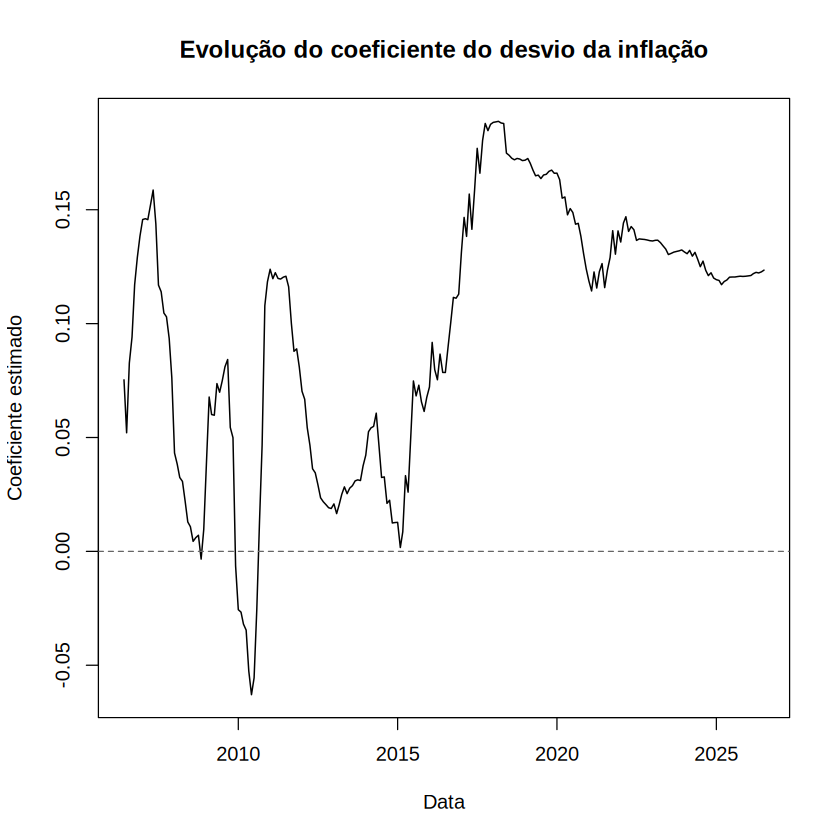

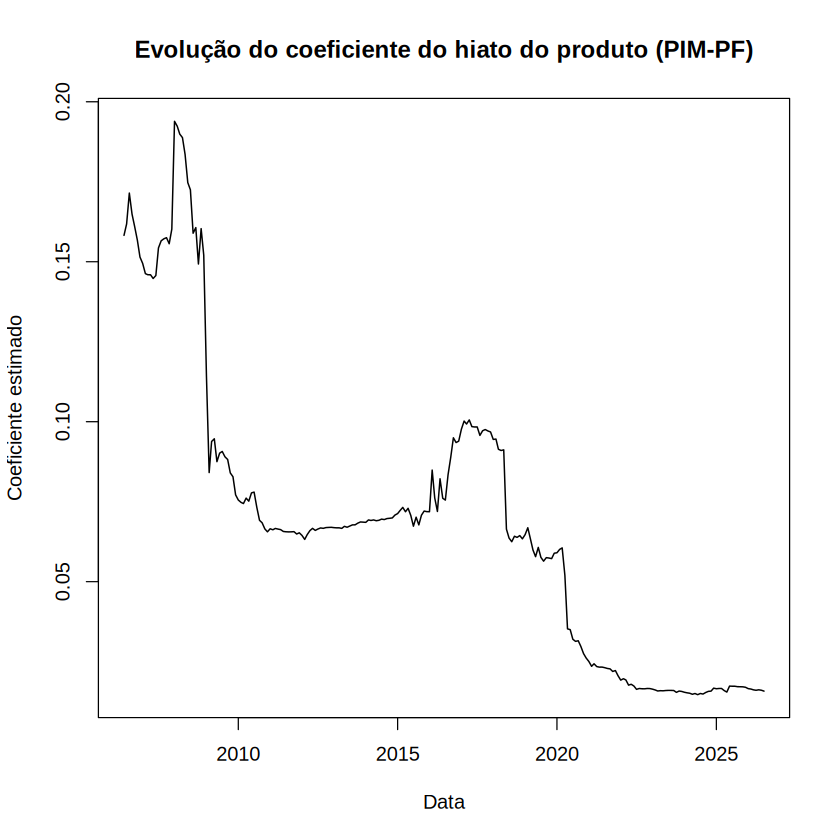

In [ ]:

# ============================================================
# MODELO 3 — GRÁFICOS DOS COEFICIENTES AUXILIARES
# ============================================================

grafico_janela_m3 <- function(coluna, titulo) {

  y <- resultados_janelas_m3[[coluna]]

  plot(
    resultados_janelas_m3$Data,
    y,
    type = "l",
    lwd = 1.2,
    col = "black",
    main = titulo,
    xlab = "Data",
    ylab = "Coeficiente estimado"
  )

  if (min(y) <= 0 && max(y) >= 0) {
    abline(h = 0, lty = 2, col = "gray40")
  }
}

grafico_janela_m3(
  "beta_selic",
  "Evolução do coeficiente da Selic defasada"
)

grafico_janela_m3(
  "beta_inflacao",
  "Evolução do coeficiente do desvio da inflação"
)

grafico_janela_m3(
  "beta_hiato",
  "Evolução do coeficiente do hiato do produto (PIM-PF)"
)


In [ ]:

# ============================================================
# MODELO 3 — TESTE QLR (SUP-F)
# ============================================================

library(strucchange)

# 1. Estatísticas F para possíveis pontos de quebra
fstats_m3 <- strucchange::Fstats(
  formula_m3,
  data = dados_modelo3,
  from = 0.15,
  to = 0.85
)

# 2. Teste sup-F
teste_qlr_m3 <- strucchange::sctest(
  fstats_m3,
  type = "supF"
)

cat("\n========== TESTE QLR — MODELO 3 ==========\n")
print(teste_qlr_m3)

# 3. Localizar a maior estatística F
valores_F_m3 <- as.numeric(fstats_m3$Fstats)

indice_max_m3 <- which.max(valores_F_m3)

# Índices de observação correspondentes aos pontos testados
indices_testados_m3 <- seq.int(
  from = fstats_m3$from,
  to = fstats_m3$to
)

indice_quebra_qlr_m3 <- indices_testados_m3[indice_max_m3]

cat("\n========== QUEBRA CANDIDATA — QLR ==========\n")
cat("Estatística máxima:",
    round(max(valores_F_m3), 6), "\n")
cat("Observação da quebra:",
    indice_quebra_qlr_m3, "\n")
cat("Último mês do primeiro segmento:",
    format(dados_modelo3$Data[indice_quebra_qlr_m3],
           "%m/%Y"), "\n")
cat("Primeiro mês do segundo segmento:",
    format(dados_modelo3$Data[indice_quebra_qlr_m3 + 1],
           "%m/%Y"), "\n")

# 4. Gráfico
plot(
  fstats_m3,
  main = "Teste QLR (sup-F) — Modelo 3",
  xlab = "Tempo",
  ylab = "Estatística F"
)



========== TESTE QLR — MODELO 3 ==========

	supF test

data:  fstats_m3
sup.F = 21.972, p-value = 0.005161



ERROR: Error in seq.int(from = fstats_m3$from, to = fstats_m3$to): 'from' must be of length 1



========== QUEBRA CANDIDATA — QLR ==========
Estatística máxima: 21.97249 
Observação da quebra: 1 
Último mês do primeiro segmento: 07/1999 
Primeiro mês do segundo segmento: 08/1999 


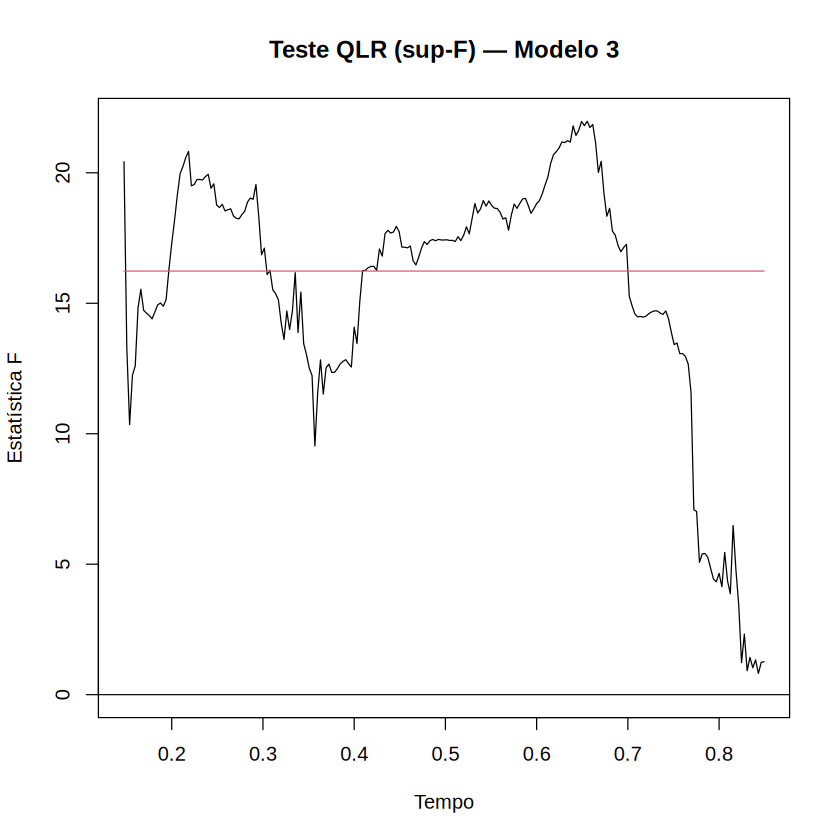

In [ ]:

# ============================================================
# MODELO 3 — CORREÇÃO DA IDENTIFICAÇÃO DA QUEBRA QLR
# ============================================================

# 1. Extrair as estatísticas F
serie_F_m3 <- fstats_m3$Fstats
valores_F_m3 <- as.numeric(serie_F_m3)

stopifnot(
  length(valores_F_m3) > 0,
  all(is.finite(valores_F_m3))
)

# 2. Identificar a posição da maior estatística
posicao_max_m3 <- which.max(valores_F_m3)

# 3. Recuperar o índice amostral pelo tempo da série
indice_quebra_qlr_m3 <- as.integer(
  round(as.numeric(
    stats::time(serie_F_m3)[posicao_max_m3]
  ))
)

# 4. Validar o índice
stopifnot(
  indice_quebra_qlr_m3 >= 1,
  indice_quebra_qlr_m3 < nrow(dados_modelo3)
)

# 5. Apresentar os resultados
cat("\n========== QUEBRA CANDIDATA — QLR ==========\n")

cat(
  "Estatística máxima:",
  round(max(valores_F_m3), 6),
  "\n"
)

cat(
  "Observação da quebra:",
  indice_quebra_qlr_m3,
  "\n"
)

cat(
  "Último mês do primeiro segmento:",
  format(
    dados_modelo3$Data[indice_quebra_qlr_m3],
    "%m/%Y"
  ),
  "\n"
)

cat(
  "Primeiro mês do segundo segmento:",
  format(
    dados_modelo3$Data[indice_quebra_qlr_m3 + 1],
    "%m/%Y"
  ),
  "\n"
)

# 6. Gráfico do QLR
plot(
  fstats_m3,
  main = "Teste QLR (sup-F) — Modelo 3",
  xlab = "Tempo",
  ylab = "Estatística F"
)


In [ ]:

# ============================================================
# MODELO 3 — IDENTIFICAÇÃO CORRETA DA QUEBRA QLR
# ============================================================

valores_F_m3 <- as.numeric(fstats_m3$Fstats)

posicao_max_m3 <- which.max(valores_F_m3)

# Escala temporal normalizada do Fstats
tempo_max_m3 <- as.numeric(
  time(fstats_m3$Fstats)[posicao_max_m3]
)

# Converter a fração amostral para observação
indice_quebra_qlr_m3 <- as.integer(
  round(tempo_max_m3 * nrow(dados_modelo3))
)

stopifnot(
  indice_quebra_qlr_m3 >= floor(0.15 * nrow(dados_modelo3)),
  indice_quebra_qlr_m3 <= ceiling(0.85 * nrow(dados_modelo3)),
  indice_quebra_qlr_m3 < nrow(dados_modelo3)
)

cat("\n========== QUEBRA CANDIDATA — QLR ==========\n")

cat("Estatística máxima:",
    round(max(valores_F_m3), 6), "\n")

cat("Fração amostral:",
    round(tempo_max_m3, 6), "\n")

cat("Observação da quebra:",
    indice_quebra_qlr_m3, "\n")

cat("Último mês do primeiro segmento:",
    format(
      dados_modelo3$Data[indice_quebra_qlr_m3],
      "%m/%Y"
    ), "\n")

cat("Primeiro mês do segundo segmento:",
    format(
      dados_modelo3$Data[indice_quebra_qlr_m3 + 1],
      "%m/%Y"
    ), "\n")



========== QUEBRA CANDIDATA — QLR ==========
Estatística máxima: 21.97249 
Fração amostral: 0.655385 
Observação da quebra: 213 
Último mês do primeiro segmento: 03/2017 
Primeiro mês do segundo segmento: 04/2017 



========== BAI-PERRON — MODELO 3 ==========

	 Optimal (m+1)-segment partition: 

Call:
breakpoints.formula(formula = formula_m3, h = 0.15, breaks = 5, 
    data = dados_modelo3)

Breakpoints at observation number:
                         
m = 1             213    
m = 2   48 96            
m = 3   48 96     218    
m = 4   48 96 145 220    
m = 5   48 96 145 223 273

Corresponding to breakdates:
                                                                               
m = 1                                                         0.655384615384615
m = 2   0.147692307692308 0.295384615384615                                    
m = 3   0.147692307692308 0.295384615384615                   0.670769230769231
m = 4   0.147692307692308 0.295384615384615 0.446153846153846 0.676923076923077
m = 5   0.147692307692308 0.295384615384615 0.446153846153846 0.686153846153846
            
m = 1       
m = 2       
m = 3       
m = 4       
m = 5   0.84

Fit:
                                  

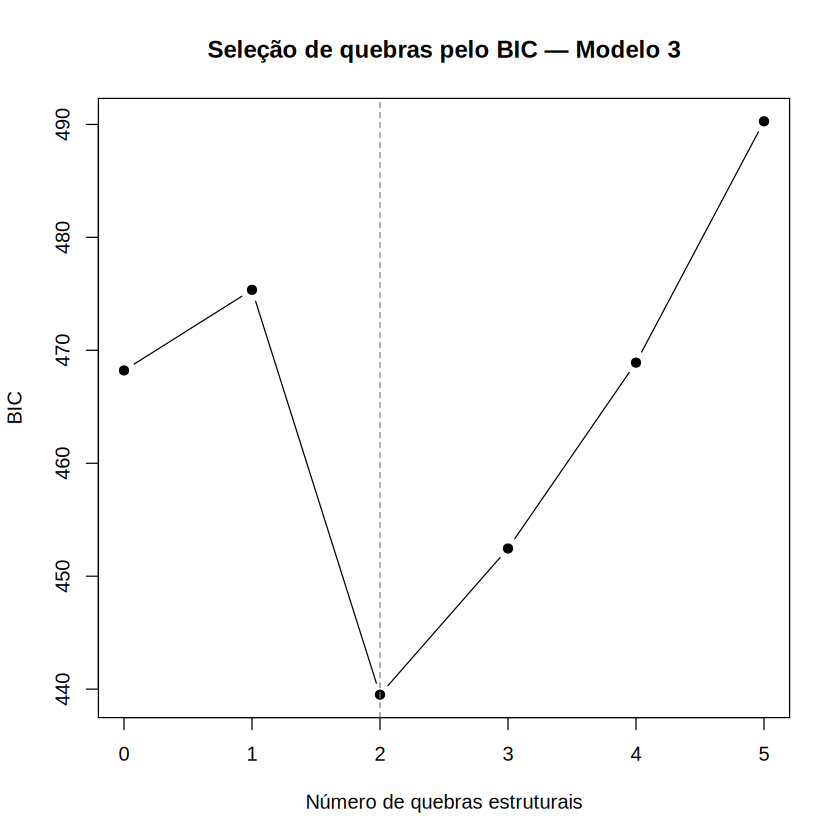

In [ ]:

# ============================================================
# MODELO 3 — BAI-PERRON E SELEÇÃO PELO BIC
# ============================================================

# 1. Estimar modelos com até cinco quebras
bp_m3 <- strucchange::breakpoints(
  formula_m3,
  data = dados_modelo3,
  h = 0.15,
  breaks = 5
)

# 2. Resumo completo
resumo_bp_m3 <- summary(bp_m3)

cat("\n========== BAI-PERRON — MODELO 3 ==========\n")
print(resumo_bp_m3)

# 3. Extrair BIC para 0 a 5 quebras
bic_m3 <- as.numeric(
  resumo_bp_m3$RSS["BIC", ]
)

stopifnot(
  length(bic_m3) == 6,
  all(is.finite(bic_m3))
)

# 4. Selecionar número de quebras pelo menor BIC
numero_quebras_m3 <- which.min(bic_m3) - 1L

tabela_bic_m3 <- data.frame(
  Quebras = 0:5,
  BIC = bic_m3
)

cat("\n========== SELEÇÃO PELO BIC ==========\n")
print(
  transform(
    tabela_bic_m3,
    BIC = round(BIC, 4)
  ),
  row.names = FALSE
)

cat(
  "\nNúmero de quebras selecionado:",
  numero_quebras_m3,
  "\n"
)

# 5. Recuperar as quebras selecionadas
if (numero_quebras_m3 > 0) {

  bp_selecionado_m3 <- strucchange::breakpoints(
    bp_m3,
    breaks = numero_quebras_m3
  )

  indices_bp_m3 <- bp_selecionado_m3$breakpoints

  tabela_quebras_m3 <- data.frame(
    Observacao = indices_bp_m3,
    Ultimo_mes_regime = format(
      dados_modelo3$Data[indices_bp_m3],
      "%m/%Y"
    ),
    Primeiro_mes_regime_seguinte = format(
      dados_modelo3$Data[indices_bp_m3 + 1],
      "%m/%Y"
    )
  )

  cat("\n========== DATAS DAS QUEBRAS ==========\n")
  print(tabela_quebras_m3, row.names = FALSE)

} else {

  bp_selecionado_m3 <- NULL
  indices_bp_m3 <- integer(0)

  cat("\nBIC selecionou nenhuma quebra.\n")
}

# 6. Gráfico do BIC
plot(
  0:5,
  bic_m3,
  type = "b",
  pch = 19,
  xlab = "Número de quebras estruturais",
  ylab = "BIC",
  main = "Seleção de quebras pelo BIC — Modelo 3"
)

abline(
  v = numero_quebras_m3,
  lty = 2,
  col = "gray50"
)


In [ ]:

# ============================================================
# MODELO 3 — ESTIMAÇÃO DOS REGIMES
# NEWEY-WEST + MÉTODO DELTA
# ============================================================

# 1. Conferência das quebras selecionadas
stopifnot(
  numero_quebras_m3 == 2,
  identical(as.integer(indices_bp_m3), c(48L, 96L))
)

# 2. Definir os limites dos regimes
limites_m3 <- c(
  0L,
  as.integer(indices_bp_m3),
  nrow(dados_modelo3)
)

# 3. Função de estimação por regime
estimar_regime_m3 <- function(dados, nome_regime) {

  modelo <- lm(formula_m3, data = dados)

  V <- sandwich::NeweyWest(
    modelo,
    lag = NULL,
    prewhite = FALSE,
    adjust = TRUE
  )

  teste_auxiliar <- lmtest::coeftest(
    modelo,
    vcov. = V
  )

  b <- coef(modelo)

  rho <- unname(b["Selic_L1"])
  d <- 1 - rho

  if (abs(d) < 1e-8) {
    stop("Rho muito próximo de 1 no ", nome_regime)
  }

  # Recuperação dos parâmetros estruturais
  parametros <- c(
    alpha = unname(b["(Intercept)"]),
    rho = rho,
    phi_pi = unname(b["Desvio_Inflacao_L1"]) / d,
    phi_y = unname(b["Hiato_PIM_L1"]) / d
  )

  # Jacobiana do método delta
  J <- matrix(
    0,
    nrow = 4,
    ncol = 4,
    dimnames = list(names(parametros), names(b))
  )

  J["alpha", "(Intercept)"] <- 1
  J["rho", "Selic_L1"] <- 1

  J["phi_pi", "Selic_L1"] <-
    unname(b["Desvio_Inflacao_L1"]) / d^2

  J["phi_pi", "Desvio_Inflacao_L1"] <- 1 / d

  J["phi_y", "Selic_L1"] <-
    unname(b["Hiato_PIM_L1"]) / d^2

  J["phi_y", "Hiato_PIM_L1"] <- 1 / d

  V_estrutural <- J %*% V %*% t(J)

  ep <- sqrt(diag(V_estrutural))

  estatistica_t <- parametros / ep

  valor_p <- 2 * pt(
    abs(estatistica_t),
    df = df.residual(modelo),
    lower.tail = FALSE
  )

  tabela <- data.frame(
    Regime = nome_regime,
    Parametro = names(parametros),
    Estimativa = as.numeric(parametros),
    Erro_padrao_NW = as.numeric(ep),
    Estatistica_t = as.numeric(estatistica_t),
    Valor_p = as.numeric(valor_p)
  )

  informacoes <- data.frame(
    Regime = nome_regime,
    Inicio = format(min(dados$Data), "%m/%Y"),
    Fim = format(max(dados$Data), "%m/%Y"),
    Observacoes = nrow(dados),
    R2 = summary(modelo)$r.squared,
    R2_Ajustado = summary(modelo)$adj.r.squared
  )

  list(
    modelo = modelo,
    teste_auxiliar = teste_auxiliar,
    tabela = tabela,
    informacoes = informacoes
  )
}

# 4. Estimar os três regimes
regimes_m3 <- lapply(1:3, function(i) {

  inicio <- limites_m3[i] + 1L
  fim <- limites_m3[i + 1L]

  dados_regime <- dados_modelo3[inicio:fim, , drop = FALSE]

  estimar_regime_m3(
    dados_regime,
    paste("Regime", i)
  )
})

# 5. Consolidar resultados
tabela_regimes_m3 <- do.call(
  rbind,
  lapply(regimes_m3, function(x) x$tabela)
)

informacoes_regimes_m3 <- do.call(
  rbind,
  lapply(regimes_m3, function(x) x$informacoes)
)

rownames(tabela_regimes_m3) <- NULL
rownames(informacoes_regimes_m3) <- NULL

# 6. Validações
stopifnot(
  nrow(tabela_regimes_m3) == 12,
  sum(informacoes_regimes_m3$Observacoes) == 325,
  all(is.finite(tabela_regimes_m3$Estimativa)),
  all(is.finite(tabela_regimes_m3$Erro_padrao_NW))
)

# 7. Apresentação
cat("\n========== PARÂMETROS ESTRUTURAIS ==========\n")

print(
  transform(
    tabela_regimes_m3,
    Estimativa = round(Estimativa, 5),
    Erro_padrao_NW = round(Erro_padrao_NW, 5),
    Estatistica_t = round(Estatistica_t, 4),
    Valor_p = signif(Valor_p, 5)
  ),
  row.names = FALSE
)

cat("\n========== INFORMAÇÕES DOS REGIMES ==========\n")

print(
  transform(
    informacoes_regimes_m3,
    R2 = round(R2, 4),
    R2_Ajustado = round(R2_Ajustado, 4)
  ),
  row.names = FALSE
)

# 8. Coeficientes auxiliares de cada regime
for (i in seq_along(regimes_m3)) {

  cat(
    "\n========== REGIME", i,
    ": COEFICIENTES AUXILIARES ==========\n"
  )

  print(regimes_m3[[i]]$teste_auxiliar)
}



========== PARÂMETROS ESTRUTURAIS ==========
   Regime Parametro Estimativa Erro_padrao_NW Estatistica_t     Valor_p
 Regime 1     alpha    1.10216        0.81926        1.3453  1.8542e-01
 Regime 1       rho    0.92548        0.04531       20.4238  4.4700e-24
 Regime 1    phi_pi    2.09660        1.11386        1.8823  6.6421e-02
 Regime 1     phi_y    0.12135        0.65844        0.1843  8.5462e-01
 Regime 2     alpha   -0.90360        0.72186       -1.2518  2.1727e-01
 Regime 2       rho    1.05171        0.04595       22.8879  4.5417e-26
 Regime 2    phi_pi    2.74648        1.58967        1.7277  9.1055e-02
 Regime 2     phi_y   -4.56869        3.96038       -1.1536  2.5489e-01
 Regime 3     alpha    0.13700        0.07956        1.7220  8.6441e-02
 Regime 3       rho    0.97030        0.00903      107.4988 2.1983e-195
 Regime 3    phi_pi    3.76556        0.95469        3.9443  1.0696e-04
 Regime 3     phi_y    1.48811        0.57458        2.5899  1.0227e-02

========== INFORM

In [ ]:

# ============================================================
# MODELO 3 — TESTES DE CHOW
# DATAS INSTITUCIONAIS
# ============================================================

datas_chow_m3 <- data.frame(
  Presidente = c(
    "Alexandre Tombini",
    "Ilan Goldfajn",
    "Roberto Campos Neto",
    "Gabriel Galipolo"
  ),
  Inicio = as.Date(c(
    "2011-01-01",
    "2016-06-01",
    "2019-03-01",
    "2025-01-01"
  ))
)

teste_chow_m3 <- function(data_quebra, presidente) {

  antes <- dados_modelo3[
    dados_modelo3$Data < data_quebra, ,
    drop = FALSE
  ]

  depois <- dados_modelo3[
    dados_modelo3$Data >= data_quebra, ,
    drop = FALSE
  ]

  n1 <- nrow(antes)
  n2 <- nrow(depois)

  # Quatro parâmetros, incluindo o intercepto
  k <- length(coef(modelo3))

  if (n1 <= k || n2 <= k) {
    stop("Observações insuficientes: ", presidente)
  }

  modelo_antes <- lm(formula_m3, data = antes)
  modelo_depois <- lm(formula_m3, data = depois)

  stopifnot(
    !anyNA(coef(modelo_antes)),
    !anyNA(coef(modelo_depois))
  )

  rss_restrito <- sum(resid(modelo3)^2)

  rss_irrestrito <- sum(resid(modelo_antes)^2) +
    sum(resid(modelo_depois)^2)

  gl1 <- k
  gl2 <- n1 + n2 - 2 * k

  F_chow <- (
    (rss_restrito - rss_irrestrito) / gl1
  ) / (
    rss_irrestrito / gl2
  )

  valor_p <- pf(
    F_chow,
    df1 = gl1,
    df2 = gl2,
    lower.tail = FALSE
  )

  data.frame(
    Presidente = presidente,
    Data = format(data_quebra, "%m/%Y"),
    N_antes = n1,
    N_depois = n2,
    F = F_chow,
    Valor_p = valor_p,
    Significativo_5pct = valor_p < 0.05
  )
}

resultados_chow_m3 <- do.call(
  rbind,
  lapply(seq_len(nrow(datas_chow_m3)), function(i) {
    teste_chow_m3(
      datas_chow_m3$Inicio[i],
      datas_chow_m3$Presidente[i]
    )
  })
)

stopifnot(
  nrow(resultados_chow_m3) == 4,
  all(
    resultados_chow_m3$N_antes +
    resultados_chow_m3$N_depois == 325
  ),
  all(is.finite(resultados_chow_m3$F)),
  all(is.finite(resultados_chow_m3$Valor_p))
)

cat("\n========== TESTES DE CHOW — MODELO 3 ==========\n")

print(
  transform(
    resultados_chow_m3,
    F = round(F, 4),
    Valor_p = signif(Valor_p, 5)
  ),
  row.names = FALSE
)



========== TESTES DE CHOW — MODELO 3 ==========
          Presidente    Data N_antes N_depois      F    Valor_p
   Alexandre Tombini 01/2011     138      187 4.0649 0.00314780
       Ilan Goldfajn 06/2016     203      122 5.2383 0.00042523
 Roberto Campos Neto 03/2019     236       89 3.6671 0.00616510
    Gabriel Galipolo 01/2025     306       19 1.9995 0.09441000
 Significativo_5pct
               TRUE
               TRUE
               TRUE
              FALSE
